# Sentiment analysis con n-gramas (IMDb)

Proyecto 1 de MdT. La idea en papel es bastante simple: agarrar 50,000 reseñas de IMDb, convertirlas en conteos de unigramas, bigramas y trigramas, y ver qué tan bien Naive Bayes, regresión logística y un SVM lineal adivinan si a la persona le gustó la película o no. Lo interesante no es tanto el accuracy (que anda arriba del 89%, o sea que el problema se resuelve "fácil") sino en qué se equivoca el modelo, porque ahí se ve exactamente dónde una bolsa de palabras deja de entender lo que alguien quiso decir.

Todo el código pesado vive en los módulos `.py` de esta carpeta (`data`, `preprocessing`, `features`, `models`, `evaluation`, `error_analysis`), el notebook nada más los va llamando en orden y cuenta qué pasa en cada paso.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from error_analysis import misclassified, tag_rates, top_features
from evaluation import accuracy_by_group, add_length_bucket, compute_metrics, plot_confusion_matrix
from features import NGRAM_CONFIGS
from models import build_pipeline, decision_scores, get_classifiers
from preprocessing import tokenize
from run_pipeline import compare_ngrams_on_dev, load_preprocessed

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
# Un color fijo por modelo, el mismo en todas las gráficas.
MODEL_COLORS = {"Naive Bayes": "#2a78d6", "Logistic Regression": "#eb6834", "Linear SVM": "#1baf7a"}

## 1. Los datos

Las reseñas son del dataset de Maas et al. (2011): 25k para entrenar y 25k para probar, mitad positivas y mitad negativas. El servidor de Stanford no respondió (ni desde mi red ni desde ningún otro lado), así que `data.py` cae solito a la copia de Hugging Face, que tiene exactamente las mismas reseñas y etiquetas pero SIN la calificación de estrellas. Por eso la columna `rating` sale vacía y el análisis por intensidad de la polaridad (que era opcional) se queda fuera.

Del train saqué un 20% como dev, estratificado y con semilla 42, para comparar configuraciones. El test no se toca hasta el final, porque si eliges el modelo viendo el test el número que reportas ya viene inflado.

In [2]:
train, dev, test = load_preprocessed()
for name, df in (("train", train), ("dev", dev), ("test", test)):
    print(f"{name:>5}: {len(df):>6} reseñas, {df['label'].mean():.0%} positivas")
train[["text", "label"]].head()

train:  20000 reseñas, 50% positivas
  dev:   5000 reseñas, 50% positivas
 test:  25000 reseñas, 50% positivas


,text,label
0,"I have always been a huge James Bond fanatic! I have seen almost all of the films except for Die Another Day, and Th...",1
1,"I am a Christian and I say this movie had terrible acting, unreal situations and a completely facade front for Chris...",0
2,"Neatly sandwiched between THE STRANGER, a small film noir picture that proved Welles can do a formidable genre work ...",1
3,"Years ago I did follow a soap on TV. So I was curious about this movie, and I was so rewarded for finding it. It's a...",1
4,"Here's a gritty, get-the-bad guys revenge story starring a relentless and rough Denzel Washington. He's three person...",1


## 2. Preprocesamiento

Lo que hace `preprocessing.py`, en orden: quita las etiquetas `<br />` que vienen pegadas en casi todas las reseñas, pasa todo a minúsculas, expande los `n't` a `not` ("didn't" se vuelve "did not"), tokeniza con el `TreebankWordTokenizer` de NLTK y le quita la puntuación a los tokens.

La decisión que sí importa es la de las stopwords. La lista de sklearn trae "not", "no", "never" y compañía, y si las quitas a ciegas el bigrama `not good` simplemente nunca existe, que es justo lo que se supone que los n-gramas deberían capturar. Por eso la lista que uso excluye las negaciones. Y al final para el experimento principal ni siquiera quité stopwords, porque cosas como `the worst` resultaron ser de los bigramas más útiles (spoiler de la sección 4).

In [3]:
sample = "I didn't like it.<br /><br />The acting wasn't BAD, but the plot? Not great!"
print("sin quitar stopwords:", tokenize(sample))
print("quitando stopwords:  ", tokenize(sample, remove_stopwords=True))

sin quitar stopwords: ['i', 'did', 'not', 'like', 'it', 'the', 'acting', 'was', 'not', 'bad', 'but', 'the', 'plot', 'not', 'great']
quitando stopwords:   ['did', 'not', 'like', 'acting', 'not', 'bad', 'plot', 'not', 'great']


In [4]:
print(train.loc[0, "text"][:400], "\n")
print(train.loc[0, "clean"][:400])

I have always been a huge James Bond fanatic! I have seen almost all of the films except for Die Another Day, and The World Is Not Enough. The graphic's for Everything Or Nothing are breathtaking! The voice talents......... WOW! I LOVE PIERCE BROSNAN! He is finally Bond in a video game! HE IS BOND! I enjoyed the past Bond games: Goldeneye, The World Is Not Enough, Agent Under Fire, and Nightfire.  

i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the graphic s for everything or nothing are breathtaking the voice talents wow i love pierce brosnan he is finally bond in a video game he is bond i enjoyed the past bond games goldeneye the world is not enough agent under fire and nightfire this one is definitely


## 3. Comparación de n-gramas en dev

Cada review se vuelve un vector de conteos con `CountVectorizer` (con `min_df=2`, o sea que un n-grama que sale en una sola reseña se descarta, porque con trigramas el vocabulario explota con frases que nunca se repiten y eso nada más ocupa memoria). Entreno los tres clasificadores con cinco rangos de n-gramas: solo unigramas, solo bigramas, solo trigramas, uni+bi y uni+bi+tri. Son 15 modelos y tardan varios minutos, paciencia.

In [5]:
dev_results = compare_ngrams_on_dev(train, dev)
dev_results.pivot(index="ngrams", columns="model", values="accuracy").loc[list(NGRAM_CONFIGS)].round(4)

  unigram     Naive Bayes          acc=0.8436 (10s)


  unigram     Logistic Regression  acc=0.8872 (22s)


  unigram     Linear SVM           acc=0.8814 (66s)


  bigram      Naive Bayes          acc=0.8758 (35s)


  bigram      Logistic Regression  acc=0.8812 (41s)


  bigram      Linear SVM           acc=0.8814 (56s)


... (6 outputs left out)

  uni+bi+tri  Naive Bayes          acc=0.8812 (66s)


  uni+bi+tri  Logistic Regression  acc=0.9028 (111s)


  uni+bi+tri  Linear SVM           acc=0.9022 (106s)


model,Linear SVM,Logistic Regression,Naive Bayes
ngrams,,,
unigram,0.8814,0.8872,0.8436
bigram,0.8814,0.8812,0.8758
trigram,0.8466,0.8514,0.8702
uni+bi,0.8980,0.9028,0.8718
uni+bi+tri,0.9022,0.9028,0.8812


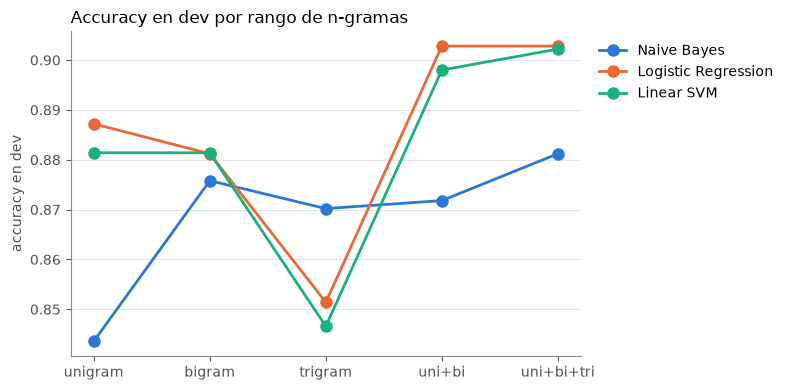

model,Linear SVM,Logistic Regression,Naive Bayes
ngrams,,,
unigram,44124,44124,44124
bigram,316127,316127,316127
trigram,384387,384387,384387
uni+bi,360251,360251,360251
uni+bi+tri,744638,744638,744638


In [6]:
order = list(NGRAM_CONFIGS)
fig, ax = plt.subplots(figsize=(8, 4))
for model, color in MODEL_COLORS.items():
    acc = dev_results[dev_results["model"] == model].set_index("ngrams").loc[order, "accuracy"]
    ax.plot(order, acc, color=color, linewidth=2, marker="o", markersize=8, label=model)
ax.set_ylabel("accuracy en dev")
ax.set_title("Accuracy en dev por rango de n-gramas", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("results/figures/dev_ngram_comparison.png", dpi=150)
plt.show()
dev_results.pivot(index="ngrams", columns="model", values="n_features").loc[order]

Lo que se ve:

- **Mezclar gana, los trigramas solos pierden.** Pasar de unigramas a uni+bi sube como punto y medio en regresión logística y SVM. Los trigramas solos son los peores para los modelos discriminativos, y tiene sentido: casi ningún trigrama se repite lo suficiente como para aprender algo de él (hay que ver la tabla de `n_features`, son muchísimos y casi todos rarísimos).
- **Naive Bayes es el que más agradece los n-gramas largos.** Como asume que cada palabra es independiente de las demás, los bigramas le regalan justo el contexto que el modelo por sí solo no tiene.
- **Agregar trigramas a uni+bi ya casi no aporta** en regresión logística y SVM, cuesta el doble de tiempo y más del doble de features por unas milésimas (o nada).

## 4. Evaluación en test

Para cada modelo me quedo con el rango de n-gramas que dio mejor F1 en dev, lo reentreno con train+dev juntos (más datos, mismo modelo) y ahora sí lo pruebo una sola vez contra las 25k reseñas de test.

In [7]:
test = add_length_bucket(test)
train_dev = pd.concat([train, dev], ignore_index=True)
best_configs = dev_results.loc[dev_results.groupby("model")["f1"].idxmax()]

rows, fitted = [], {}
for _, row in best_configs.iterrows():
    pipe = build_pipeline(get_classifiers()[row["model"]], NGRAM_CONFIGS[row["ngrams"]])
    pipe.fit(train_dev["clean"], train_dev["label"])
    y_pred = pipe.predict(test["clean"])
    rows.append({"model": row["model"], "ngrams": row["ngrams"], **compute_metrics(test["label"], y_pred)})
    fitted[row["model"]] = (pipe, y_pred)

test_results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
test_results.round(4)

,model,ngrams,accuracy,precision,recall,f1
0,Linear SVM,uni+bi+tri,0.8981,0.8974,0.8990,0.8982
1,Logistic Regression,uni+bi,0.8971,0.8960,0.8986,0.8973
2,Naive Bayes,uni+bi+tri,0.8715,0.8904,0.8474,0.8683


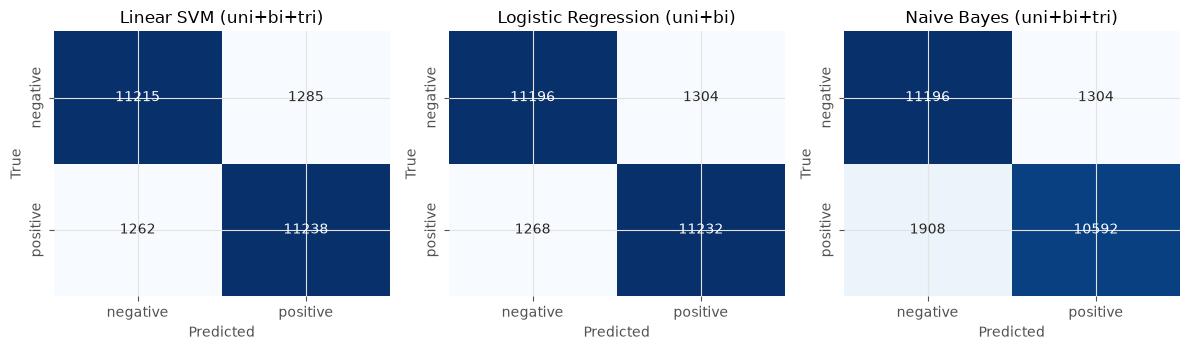

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, model in zip(axes, test_results["model"]):
    ngrams = test_results.set_index("model").loc[model, "ngrams"]
    plot_confusion_matrix(test["label"], fitted[model][1], f"{model} ({ngrams})", ax=ax)
fig.tight_layout()
plt.show()

Los tres quedan arriba del 87% y la regresión logística y el SVM prácticamente empatados (la diferencia es de décimas, ni de broma la defendería como significativa). Naive Bayes se queda un poco atrás y en su matriz se nota hacia dónde se equivoca más: tiene más falsos negativos que falsos positivos, o sea que se pone pesimista con las reseñas buenas. Los otros dos se equivocan más o menos parejo para los dos lados.

### Por longitud de la reseña

Con el mejor modelo, separo las reseñas por número de tokens.

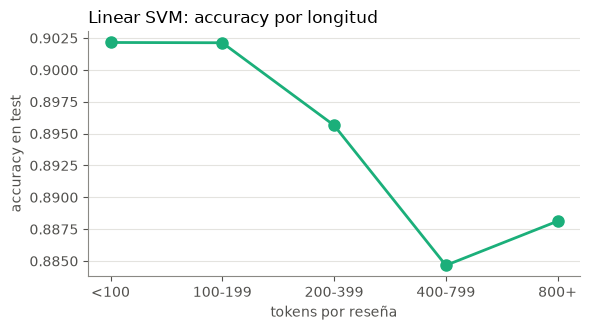

,length_bucket,accuracy,n
0,<100,0.902153,3066
1,100-199,0.902131,11638
2,200-399,0.895649,7101
3,400-799,0.884657,2757
4,800+,0.888128,438


In [9]:
best_model = test_results.loc[0, "model"]
best_pipe, best_pred = fitted[best_model]
by_length = accuracy_by_group(test, best_pred, "length_bucket")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(by_length["length_bucket"].astype(str), by_length["accuracy"], color=MODEL_COLORS[best_model],
        linewidth=2, marker="o", markersize=8)
ax.set_xlabel("tokens por reseña")
ax.set_ylabel("accuracy en test")
ax.set_title(f"{best_model}: accuracy por longitud", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
by_length

Las reseñas largas salen ligeramente peor. Mi sospecha (y la sección de errores la confirma bastante) es que una reseña larga tiene espacio para hacer de todo: contar la trama completa, comparar con otras películas, quejarse de la edición en DVD y al final dar el veredicto en una sola línea. Con conteos, ese veredicto pesa lo mismo que cualquier otra oración del texto.

### Qué aprendió el modelo

Los n-gramas con más peso hacia cada lado.

In [10]:
top_features(best_pipe, k=15).round(3)

,negative_ngram,negative_weight,positive_ngram,positive_weight
0,worst,-0.284,excellent,0.239
1,awful,-0.275,7/10,0.235
2,boring,-0.263,perfect,0.201
3,4/10,-0.242,wonderful,0.187
4,waste,-0.221,superb,0.174
5,disappointing,-0.220,7,0.171
6,terrible,-0.215,enjoyable,0.166
7,disappointment,-0.199,amazing,0.158
8,dull,-0.199,great,0.147
9,the worst,-0.192,brilliant,0.142


La mayoría son exactamente lo que uno esperaría (`worst`, `awful`, `waste`, `excellent`, `perfect`), pero aparecen `7/10` y `4/10` (y hasta `7` solito) entre los más fuertes. Hay gente que escribe su calificación dentro de la reseña, y el modelo aprendió a leer ESA calificación en vez del sentimiento del texto. No es trampa como tal, pero sí es un atajo: en un dominio donde nadie escribe "7/10" esa señal desaparece y el modelo se queda con menos de lo que creemos que sabe.

## 5. Análisis de errores

Primero lo automático: `error_analysis.py` etiqueta cada reseña con pistas lingüísticas (si tiene negaciones, conectores de contraste tipo "but" o "however", o comillas y frases que huelen a sarcasmo) y compara qué tan seguido salen en los errores contra el total.

In [11]:
errors = misclassified(test, best_pred, decision_scores(best_pipe, test["clean"]))
print(f"{len(errors)} errores de {len(test)} reseñas")
tag_rates(test, errors).query("tag != 'mixed'").round(3)

2547 errores de 25000 reseñas


,tag,pct_of_errors,pct_of_all
0,negation,0.879,0.884
1,contrast,0.836,0.796
2,sarcasm?,0.463,0.445


Y aquí la heurística se cae solita. Casi 9 de cada 10 reseñas tienen alguna negación, entre errores y aciertos por igual, así que "tiene un not" no explica nada. El contraste sí sale un poco más en los errores que en el total, que ya es algo, pero tampoco mucho. Moraleja, las etiquetas automáticas sirven para filtrar pero no sustituyen leer las reseñas. Así que a leer.

Ordené los errores por qué tan seguro estaba el modelo, porque un error con mucha confianza es más interesante que uno donde el modelo de plano estaba dudando. Revisé a mano los doce más seguros, y caen en cuatro grupos.

In [12]:
def show(review_id, chars=350):
    r = test.set_index("id").loc[review_id]
    e = errors.set_index("id").loc[review_id]
    label = "positiva" if r["label"] else "negativa"
    print(f"[{review_id}] etiqueta real: {label} | confianza del error: {e['confidence']:.2f} | {r['n_tokens']} tokens")
    text = r["text"].replace("<br />", " ")
    print("INICIO:", text[:chars], "...")
    print("FINAL: ...", text[-chars:], "\n")

### a) La reseña dice "malo, malo, malo... pero me gustó"

La persona se pasa la mitad del texto destrozando la película y al final dice que vale la pena. El veredicto vive en el último párrafo (o en la última oración, de plano), y para un modelo que cuenta palabras el orden no existe, así que gana lo que más se repite. "Brain of Blood" es el caso más bonito, es una reseña de alguien que ama las películas malas precisamente por malas, y eso con n-gramas es imposible de entender.

In [13]:
for rid in ["test_15093", "test_22750", "test_19591"]:
    show(rid)

[test_15093] etiqueta real: positiva | confianza del error: 4.39 | 991 tokens
INICIO: "2001: A Space Odyssey" is set in 2001 and the main character is HAL. A computer. That's right, a computer who talks and thinks entirely on its own. This was made in 1968 and to think by 2001 it would be conceivable that computers would talk is a joke. If this was in 3064, a talking computer that had emotions and made its own decisions would be con ...
FINAL: ... e third acts are strong, but the second act meanders around, hovering in one place for what seems like eternity. There is some intriguing stuff in the film that will provoke some thought if you give it a chance. Once the start of the film makes sense the ending works much better, even if you still don't what Kubrick is trying to say, which I don't. 



[test_22750] etiqueta real: positiva | confianza del error: 3.21 | 829 tokens
INICIO: Brain of Blood starts as Abdul Amir (Reed Hadley) the leader of a country called Kahlid is close to death because of cancer, however if he dies Kahlid will tear itself apart without anyone to lead them so doctor Robert Nigserian (Grant Williams) & one of Amir's devotees Mohammed (Zandor Vorkov) have devised a plan to take Amir's dead body to Americ ...
FINAL: ... title for an exploitation film ever & as far as I'm concerned it's a highly entertaining piece of nonsense that I had a great time watching & laughing at. They just don't/can't/won't make them like this anymore, impossible to recommend to anyone looking for a good film but bad movie lovers should enjoy it. I liked it, but then again I'm just weird. 

[test_19591] etiqueta real: positiva | confianza del error: 3.13 | 421 tokens
INICIO: House of Dracula works from the same basic premise as House of Frankenstein from the year before; namely that

### b) El texto es negativo y la etiqueta dice positiva

Aquí sinceramente creo que el modelo tiene más razón que la etiqueta. Son reseñas que se leen negativas de principio a fin ("tedious, inconsistent and ultimately irrelevant", "the content pretty horrible") y aun así la persona les puso 7 estrellas o más, que es el umbral del dataset para llamarla positiva. Ya sea ruido en la etiqueta o alguien muy generoso con las estrellas, ningún modelo de texto puede acertar aquí sin ver el número.

In [14]:
for rid in ["test_17365", "test_15208", "test_24725", "test_20621"]:
    show(rid)

[test_17365] etiqueta real: positiva | confianza del error: 4.19 | 717 tokens
INICIO: "Comanche Moon" had everything going for it. For starters, Simon Wincer's back, a man who's name is synonymous with high-quality TV westerns. Unfortunately, the problems with "Moon" are something even the most talented director couldn't solve: A poor script based on a lackluster novel.  Forget historical accuracies -- as any reader of the novels ca ...
FINAL: ... ortunities with the cast, the biggest travesty is that the original Lonesome Dove novel contained so much rich backstory for the characters that would have been fascinating, utterly fascinating, to see translated on screen. Unfortunately, all that has been tossed aside in favor of McMurtry's tedious, inconsistent and ultimately irrelevant, prequel. 

[test_15208] etiqueta real: positiva | confianza del error: 3.25 | 361 tokens
INICIO: **SPOILERS AHEAD**  It is really unfortunate that a movie so well produced turns out to be  such a disappoint

[test_20621] etiqueta real: positiva | confianza del error: 2.94 | 218 tokens
INICIO: This was Laurel and Hardy's last silent film for Roach Studios. However, since the public had a real thirst for "talkies", this same short was re-made by the team just a few years later with only a few small plot changes. LAUGHING GRAVY was essentially the same plot except that Stan and Ollie were trying to hide a cute puppy from their grouchy land ...
FINAL: ...  the same thing?! Apart from being an unconvincing plot, the movie itself is pure Laurel and Hardy, with a familiar plot and familiar roles for the comedians. This film features quite a few laughs, but unfortunately isn't one of their better films to wrap up their silent careers. This aspect of their careers just seems to have ended with a whimper. 



### c) Hablan de otra cosa

Reseñas donde el sentimiento existe, pero no va dirigido a la película. La de "Killshot" se la pasa elogiando otras películas de Mickey Rourke y de Elmore Leonard, la de "Hamlet" alaba las versiones de Olivier y Branagh, la de "Happy Days" ama la serie y odia que le cambiaron la música al DVD, y la del cine saudí habla de la prohibición de los cines en Arabia Saudita (y admite que todavía no ha visto la película JAKSJASKAJSKAS). El modelo no tiene forma de saber a QUÉ objeto va cada adjetivo, nada más cuenta que aparecen.

In [15]:
for rid in ["test_6245", "test_9561", "test_5614", "test_7791"]:
    show(rid)

[test_6245] etiqueta real: negativa | confianza del error: 3.91 | 408 tokens
INICIO: Mickey Rourke hunts Diane Lane in Elmore Leonard's Killshot It is not like Mickey Rourke ever really disappeared. He has had a steady string of appearances before he burst back on the scene. He was memorable in: Domino, Sin City, Man on Fire, Once Upon a Time in Mexico, and Get Carter. But in his powerful dramatic performance in The Wrestler (2008) ...
FINAL: ... drama section, also pick up Kiss, Kiss, Bang, Bang, and Gone Baby Gone, and Before the Devil Knows Your Dead. The last has wonderful performances by Phillip Seymour Hoffman, Ethan Hawke, Marisa Tomei and Albert Finney.  Killshot flopped at the box office. More is our luck. It is certainly worth a 3-4 dollar rental, if you like this genre. 6/20/2009 



[test_9561] etiqueta real: negativa | confianza del error: 3.40 | 918 tokens
INICIO: Franco Zeffirelli's ("The Taming Of The Shrew," "Romeo And Juliet," "Jesus Of Nazareth," "Othello") third stab at transferring Shakespeare to the screen works very well, with the casting of Mel Gibson ("Mad Max," "Lethal Weapon" and pre-"The Passion Of The Christ" notoriety) in the role formerly owned by Sir Laurence Olivier (and rightly so; see my ...
FINAL: ... , only that the denouement in Branagh's version was more violent than the denouement of the previous two faithful versions (more in line with the play; Olivier toned it down...and it worked equally well) and stuck more closely to the play, with Branagh throwing in a few harmless touches of his own...to very good effect.   This version is Not Rated. 



[test_5614] etiqueta real: negativa | confianza del error: 2.90 | 651 tokens
INICIO: HAPPY DAYS was one of my favorite shows when it aired in 1974. But the critics were quick to show their ignorance combined with a total lack of a sense of humor by slamming this show because they thought it was a cheap attempt to cash-in on the success of American GRAFFITTI.  There were some similarities between American GRAFFITTI and HAPPY DAYS.   ...
FINAL: ... lf regretting my buying the DVD! Unlike the complete first season DVD, the original music on the complete second season, has been replaced with different music. While it is great that the original episodes were digitally restored to digital perfection, the removal of the original music destroyed what it was that made this show so much fun to watch! 

[test_7791] etiqueta real: negativa | confianza del error: 3.71 | 753 tokens
INICIO: This is a fact that this is the 1st Saudi feature film to be shown in cinema theaters but not in Saudi Arabia f

### d) Citar a los demás para llevarles la contraria

"Snakes on a Train" arranca resumiendo todo lo que las otras reseñas dicen de mal de la película (amateurish, waste of time) para luego defenderla. Las palabras negativas están ahí, pero en boca de otros. Es parecido al sarcasmo en el sentido de que el texto literal dice lo contrario de lo que la persona piensa, y es justo el tipo de cosa que un conteo de n-gramas no puede ver.

In [16]:
show("test_20409")

[test_20409] etiqueta real: positiva | confianza del error: 2.92 | 690 tokens
INICIO: Forget everything that you have ever read about the Mallachi Brothers' straight-to-video release "Snakes on a Train," especially if it was a negative review. This movie is way more fun than the movie that it obviously rips off: "Snakes on a Plane." Frankly, I am surprised that more people aren't rhapsodizing about this low-budget Asylum Release. In ...
FINAL: ... -top gigantic snake at the end. Incidentally, they get on board the train because a bunch of other Mexicans have bribed a train employee and the Mexicans on board think that the girl is so cute that they let her and her boyfriend on free.  I think it's better than "Snakes on a Plane" if you want a tough, little, independently produced horror movie. 



## Conclusiones

- Con conteos de n-gramas y un clasificador lineal ya se llega a ~90% de accuracy en IMDb, que para lo simple que es el método está bastante bien. La regresión logística y el SVM lineal empatan, Naive Bayes queda unos dos puntos y medio atrás.
- Los bigramas son la mejora que sí vale la pena (capturan cosas como `the worst` o `not good`). Los trigramas solos son demasiado escasos y agregados a uni+bi casi no aportan.
- Conservar las negaciones en el preprocesamiento fue una decisión obligada, no estética. Quitar stopwords a ciegas habría borrado parte de la señal.
- Los errores con más confianza casi nunca son por una negación aislada (eso los bigramas lo resuelven más o menos bien). Son por estructura, el veredicto al final después de un montón de crítica, el sentimiento dirigido a otra cosa, opiniones ajenas citadas, y un puñado de etiquetas que de plano no cuadran con el texto. Todo eso necesita algo que entienda orden y referencia (atención, un modelo de secuencias, lo que sea que no trate el texto como una bolsa), y ahí es donde los n-gramas llegan a su techo.

A final de cuentas el modelo no se equivoca por no saber qué palabras son buenas o malas, eso lo aprendió de sobra, se equivoca porque no sabe de quién ni de qué está hablando la persona cuando las dice.